# Notebook for surface precipitation plots in +4K experiments
- Figure 8

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sn
import numpy as np

In [ ]:
ref_exp = "iconml_amip_2mom_reference_4K_60s"
SDN_exp = "iconml_amip_superdropnet_sharma25_4K_60s"
DATA_DIR = "/work/ka1176/paul/realistic-superdropnet/data/"
grid_file = "iconml_amip_2mom_reference/icon_grid_0054_R02B08_G.nc"
experiments = [ref_exp,SDN_exp]
exp_names=["ref", "SDN"]

In [4]:
dayslice= slice('2020-01-17', '2020-01-22T00:00:00.000000000')

In [5]:
ds_list = []
for exp in experiments :
    ds_list.append(xr.open_dataset(DATA_DIR + f"{exp}_atm_2d_P1D_pr_01deg.nc").sel(time=dayslice) * 3600.)
atm_2d_1D_4K = xr.concat(ds_list, dim = 'exp_name')
atm_2d_1D_4K['exp_name'] = exp_names

In [6]:
ref_exp = "iconml_amip_2mom_reference_60s"
SDN_exp = "iconml_amip_superdropnet_sharma25_60s"
experiments = [ref_exp,SDN_exp]

ds_list = []
for exp in experiments :
    ds_list.append(xr.open_dataset(DATA_DIR + f"{exp}_atm_2d_P1D_pr_01deg.nc").sel(time=dayslice) * 3600.)
atm_2d_1D = xr.concat(ds_list, dim = 'exp_name')
atm_2d_1D['exp_name'] = exp_names

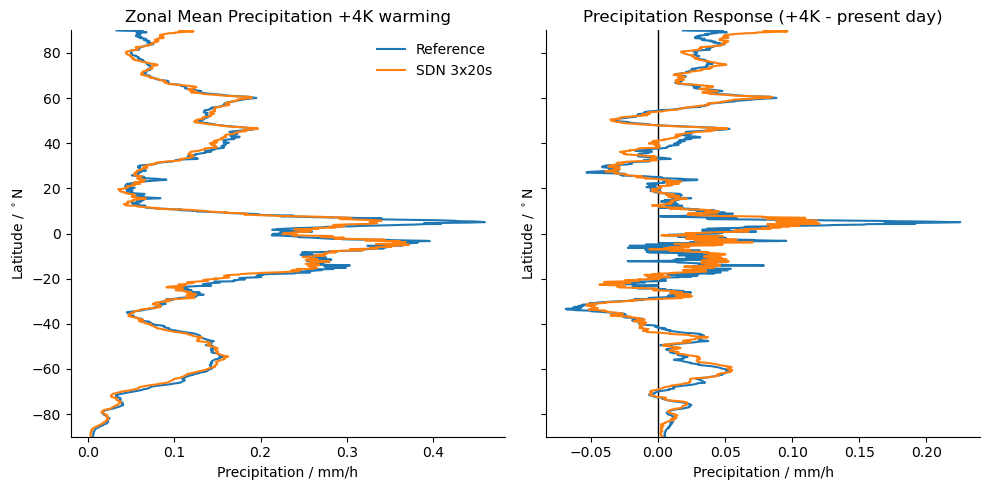

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
sn.despine(fig=fig)

ax = axes[0]
atm_2d_1D_4K.sel(exp_name="ref").mean("time").mean("lon").pr.plot(y="lat",ax=ax,label="Reference" )
SDN = atm_2d_1D_4K.sel(exp_name="SDN").mean("time").mean("lon").pr.plot(y="lat",ax=ax, label="SDN 3x20s")

ax.set_title("Zonal Mean Precipitation +4K warming")

ax.set_xlabel("Precipitation / mm/h")
ax.set_ylabel("Latitude / $^\circ$N")
ax.set_ylim(-90,90)

ax.legend(frameon=False)

ax=axes[1]

ax.plot([0,0],[-90,90], color="black", lw=1)

(atm_2d_1D_4K.sel(exp_name="ref").mean("time").mean("lon").pr - atm_2d_1D.sel(exp_name="ref").mean("time").mean("lon").pr).plot(y="lat",label="ref",ax=ax )
(atm_2d_1D_4K.sel(exp_name="SDN").mean("time").mean("lon").pr - atm_2d_1D.sel(exp_name="SDN").mean("time").mean("lon").pr).plot(y="lat",label="SDN",ax=ax )

ax.set_title("Precipitation Response (+4K - present day)")

ax.set_xlabel("Precipitation / mm/h")
ax.set_ylabel("Latitude / $^\circ$N")
ax.set_ylim(-90,90)

plt.tight_layout()

plt.savefig("../plots/precip_zonal_mean_4K.png")

